# Myopia Study: Orinda Longitudinal Study of Myopia (OLSM)

Этот ноутбук работает с локальным файлом `myopia.csv`, который лежит в директории проекта рядом с `sss.ipynb`.

Что важно про данные:

- это учебный/публичный датасет по детской миопии, связанный с Orinda Longitudinal Study of Myopia;
- обычно задача формулируется как бинарная классификация: развилась ли миопия (`MYOPIC`);
- признаки включают возраст, пол, рефракцию, параметры глаза, часы активностей и миопию родителей;
- в этом файле разделитель `;`, поэтому его нужно читать как semicolon-separated CSV.

Источники для ориентира: Kaggle dataset page `https://www.kaggle.com/datasets/mscgeorges/myopia-study`, описание OLSM/CLEERE на ClinicalTrials.gov `NCT00000169`, а также вторичный анализ Frontiers in Medicine 2025 по OLSM.

## 1. Подготовка окружения

В проекте зависимости должны быть установлены через Poetry:

```bash
poetry install
poetry run jupyter lab sss.ipynb
```

Файл `myopia.csv` должен лежать в той же папке, что и этот ноутбук.

In [ ]:
from pathlib import Path
from io import StringIO

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")

## 2. Загрузить локальный `myopia.csv`

Файл с Kaggle сохранён локально. В твоём варианте он разделён точкой с запятой, поэтому ниже используется автоопределение разделителя (`sep=None`) и движок `python`.

In [ ]:
DATA_PATH = Path("myopia.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Не найден файл {DATA_PATH.resolve()}. Положи myopia.csv рядом с sss.ipynb.")

df = pd.read_csv(DATA_PATH, sep=None, engine="python")
df.columns = [str(col).strip().strip("\"").upper() for col in df.columns]

# Если файл случайно прочитался как одна колонка, явно пробуем разделитель `;`.
if df.shape[1] == 1:
    df = pd.read_csv(DATA_PATH, sep=";")
    df.columns = [str(col).strip().strip("\"").upper() for col in df.columns]

print(f"Loaded {DATA_PATH}: {df.shape[0]} rows x {df.shape[1]} columns")
display(df.head())

## 3. Быстрый обзор: размер, типы, пропуски

In [ ]:
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")

buffer = StringIO()
df.info(buf=buffer)
print(buffer.getvalue())

missing = (
    df.isna()
    .sum()
    .rename("missing_count")
    .to_frame()
    .assign(missing_pct=lambda x: (x["missing_count"] / len(df) * 100).round(2))
    .query("missing_count > 0")
    .sort_values("missing_pct", ascending=False)
)

display(missing if not missing.empty else pd.DataFrame({"message": ["No missing values found"]}))
display(df.describe(include="all").T)

## 4. Что означают основные колонки

| Колонка | Смысл |
|---|---|
| `ID` | Идентификатор наблюдения |
| `STUDYYEAR` | Год входа ребёнка в исследование |
| `MYOPIC` | Целевая переменная: развилась миопия или нет |
| `AGE` | Возраст при первом визите |
| `GENDER` | Пол, обычно бинарное кодирование |
| `SPHEQ` | Spherical equivalent refraction: эквивалентная сферическая рефракция |
| `AL` | Axial length: осевая длина глаза |
| `ACD` | Anterior chamber depth: глубина передней камеры |
| `LT` | Lens thickness: толщина хрусталика |
| `VCD` | Vitreous chamber depth: глубина стекловидной камеры |
| `SPORTHR` | Часы спорта/активности |
| `READHR`, `COMPHR`, `STUDYHR`, `TVHR` | Часы чтения, компьютера, учёбы, телевизора |
| `DIOPTERHR` | Интегральная нагрузка ближней работы в диоптр-часах |
| `MOMMY`, `DADMY` | Миопия у матери/отца |

Медицински важные признаки для первого анализа: `SPHEQ`, `AL`, `ACD`, `LT`, `VCD`, `SPORTHR`, `DIOPTERHR`, `MOMMY`, `DADMY`.

## 5. Целевая переменная и базовые группы признаков

In [ ]:
target = "MYOPIC"
if target not in df.columns:
    raise KeyError(f"Expected target column {target!r}; available columns: {list(df.columns)}")

clinical_features = [col for col in ["SPHEQ", "AL", "ACD", "LT", "VCD"] if col in df.columns]
behavior_features = [col for col in ["SPORTHR", "READHR", "COMPHR", "STUDYHR", "TVHR", "DIOPTERHR"] if col in df.columns]
family_features = [col for col in ["MOMMY", "DADMY"] if col in df.columns]
basic_features = [col for col in ["AGE", "GENDER"] if col in df.columns]

feature_groups = {
    "basic": basic_features,
    "clinical": clinical_features,
    "behavior": behavior_features,
    "family": family_features,
}

display(pd.Series(feature_groups, name="columns"))
display(df[target].value_counts(dropna=False).rename("count").to_frame())
display((df[target].value_counts(normalize=True, dropna=False) * 100).round(2).rename("percent").to_frame())

## 6. Первичная визуализация

Здесь смотрим баланс целевой переменной, распределения ключевых клинических признаков и корреляции числовых переменных.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df, x=target, ax=axes[0])
axes[0].set_title("Target distribution")

if "SPHEQ" in df.columns:
    sns.histplot(data=df, x="SPHEQ", hue=target, kde=True, bins=30, ax=axes[1])
    axes[1].set_title("SPHEQ by target")
else:
    axes[1].axis("off")

plt.tight_layout()
plt.show()

plot_cols = [col for col in ["AGE", "SPHEQ", "AL", "ACD", "LT", "VCD", "SPORTHR", "DIOPTERHR", target] if col in df.columns]
numeric_plot_df = df[plot_cols].apply(pd.to_numeric, errors="coerce")

plt.figure(figsize=(10, 8))
sns.heatmap(numeric_plot_df.corr(), annot=True, fmt=".2f", cmap="vlag", center=0, square=True)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

## 7. Гибридная модель: линейная база + нелинейная коррекция

Идея эксперимента:

1. Логистическая регрессия даёт базовую вероятность `p_linear`.
2. На train считаем остаток `residual = y_true - p_linear`.
3. Нелинейный регрессор учится предсказывать этот остаток по тем же признакам.
4. На test итоговая вероятность считается как `p_hybrid = clip(p_linear + alpha * residual_correction, 0, 1)`.
5. `alpha` подбирается только на train через cross-validation.

Сравним три модели: `Logistic Regression`, `Gradient Boosting Classifier`, `Hybrid Residual Model`.

,alpha,cv_PR-AUC_mean,cv_PR-AUC_std
4,0.4,0.661,0.043
1,0.1,0.657,0.051
3,0.3,0.656,0.044
5,0.5,0.653,0.047
2,0.2,0.651,0.047
0,0.0,0.650,0.056
6,0.6,0.643,0.055
7,0.7,0.634,0.063
8,0.8,0.628,0.066
9,0.9,0.618,0.071


Best alpha by CV PR-AUC: 0.4


,model,ROC-AUC,PR-AUC,recall,specificity,F1,false_negative_rate,TP,FP,TN,FN
0,Logistic Regression,0.819,0.468,0.55,0.837,0.415,0.45,11,22,113,9
2,Hybrid Residual Model (alpha=0.4),0.803,0.456,0.40,0.904,0.390,0.60,8,13,122,12
1,Gradient Boosting Classifier,0.778,0.315,0.05,0.978,0.083,0.95,1,3,132,19


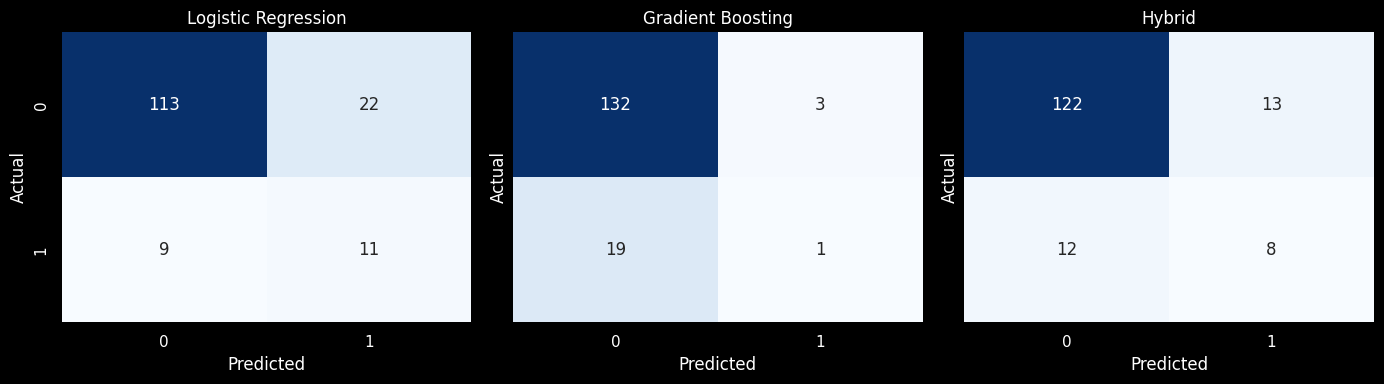

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, confusion_matrix, f1_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

candidate_features = basic_features + clinical_features + behavior_features + family_features
candidate_features = [col for col in candidate_features if col != target]

model_df = df[candidate_features + [target]].copy()
model_df[target] = pd.to_numeric(model_df[target], errors="coerce")
model_df = model_df.dropna(subset=[target])

X = model_df[candidate_features]
y = model_df[target].astype(int)

categorical_features = [col for col in ["GENDER", "MOMMY", "DADMY"] if col in X.columns]
numeric_features = [col for col in X.columns if col not in categorical_features]

numeric_scaled = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

categorical_encoded = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)

preprocess_linear = ColumnTransformer(
    transformers=[
        ("num", numeric_scaled, numeric_features),
        ("cat", categorical_encoded, categorical_features),
    ],
    remainder="drop",
)

preprocess_tree = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), numeric_features),
        ("cat", categorical_encoded, categorical_features),
    ],
    remainder="drop",
)


def make_logistic_regression() -> Pipeline:
    return Pipeline(
        steps=[
            ("preprocess", preprocess_linear),
            ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42)),
        ]
    )


def make_gradient_boosting_classifier() -> Pipeline:
    return Pipeline(
        steps=[
            ("preprocess", preprocess_tree),
            ("model", GradientBoostingClassifier(random_state=42)),
        ]
    )


def make_residual_regressor() -> Pipeline:
    return Pipeline(
        steps=[
            ("preprocess", preprocess_tree),
            (
                "model",
                GradientBoostingRegressor(
                    n_estimators=150,
                    learning_rate=0.03,
                    max_depth=2,
                    min_samples_leaf=10,
                    random_state=42,
                ),
            ),
        ]
    )


def fit_hybrid_model(X_train_part: pd.DataFrame, y_train_part: pd.Series):
    linear_model = make_logistic_regression()
    linear_model.fit(X_train_part, y_train_part)

    p_linear_train = linear_model.predict_proba(X_train_part)[:, 1]
    residual_train = y_train_part.to_numpy() - p_linear_train

    residual_model = make_residual_regressor()
    residual_model.fit(X_train_part, residual_train)

    return linear_model, residual_model


def predict_hybrid_proba(linear_model: Pipeline, residual_model: Pipeline, X_part: pd.DataFrame, alpha: float) -> np.ndarray:
    p_linear = linear_model.predict_proba(X_part)[:, 1]
    residual_correction = residual_model.predict(X_part)
    return np.clip(p_linear + alpha * residual_correction, 0, 1)


def binary_metrics(y_true: pd.Series, p_positive: np.ndarray, threshold: float = 0.5) -> dict:
    y_pred = (p_positive >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    specificity = tn / (tn + fp) if (tn + fp) else 0.0
    false_negative_rate = fn / (fn + tp) if (fn + tp) else 0.0

    return {
        "ROC-AUC": roc_auc_score(y_true, p_positive),
        "PR-AUC": average_precision_score(y_true, p_positive),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "specificity": specificity,
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "false_negative_rate": false_negative_rate,
        "TP": tp,
        "FP": fp,
        "TN": tn,
        "FN": fn,
    }


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y,
)

alpha_grid = np.round(np.linspace(0.0, 1.5, 16), 2)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
alpha_rows = []

for alpha in alpha_grid:
    fold_scores = []

    for train_idx, valid_idx in cv.split(X_train, y_train):
        X_fold_train = X_train.iloc[train_idx]
        y_fold_train = y_train.iloc[train_idx]
        X_fold_valid = X_train.iloc[valid_idx]
        y_fold_valid = y_train.iloc[valid_idx]

        linear_fold, residual_fold = fit_hybrid_model(X_fold_train, y_fold_train)
        p_valid = predict_hybrid_proba(linear_fold, residual_fold, X_fold_valid, alpha)
        fold_scores.append(average_precision_score(y_fold_valid, p_valid))

    alpha_rows.append(
        {
            "alpha": alpha,
            "cv_PR-AUC_mean": np.mean(fold_scores),
            "cv_PR-AUC_std": np.std(fold_scores),
        }
    )

alpha_results = pd.DataFrame(alpha_rows).sort_values("cv_PR-AUC_mean", ascending=False)
best_alpha = float(alpha_results.iloc[0]["alpha"])

display(alpha_results.round(3))
print(f"Best alpha by CV PR-AUC: {best_alpha}")

# Финальное обучение только на train, финальная оценка только на test.
logistic_model = make_logistic_regression()
logistic_model.fit(X_train, y_train)
p_logistic = logistic_model.predict_proba(X_test)[:, 1]

gb_classifier = make_gradient_boosting_classifier()
gb_classifier.fit(X_train, y_train)
p_gb_classifier = gb_classifier.predict_proba(X_test)[:, 1]

hybrid_linear, hybrid_residual = fit_hybrid_model(X_train, y_train)
p_hybrid = predict_hybrid_proba(hybrid_linear, hybrid_residual, X_test, best_alpha)

comparison = pd.DataFrame(
    [
        {"model": "Logistic Regression", **binary_metrics(y_test, p_logistic)},
        {"model": "Gradient Boosting Classifier", **binary_metrics(y_test, p_gb_classifier)},
        {"model": f"Hybrid Residual Model (alpha={best_alpha})", **binary_metrics(y_test, p_hybrid)},
    ]
).sort_values("PR-AUC", ascending=False)

display(comparison.round(3))

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (name, probs) in zip(
    axes,
    [
        ("Logistic Regression", p_logistic),
        ("Gradient Boosting", p_gb_classifier),
        ("Hybrid", p_hybrid),
    ],
):
    y_pred = (probs >= 0.5).astype(int)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [13]:
baseline = comparison.loc[comparison["model"] == "Logistic Regression"].iloc[0]
hybrid = comparison.loc[comparison["model"].str.startswith("Hybrid")].iloc[0]

recall_delta = hybrid["recall"] - baseline["recall"]
fnr_delta = hybrid["false_negative_rate"] - baseline["false_negative_rate"]
pr_auc_delta = hybrid["PR-AUC"] - baseline["PR-AUC"]

print("Hybrid vs Logistic Regression")
print(f"PR-AUC delta: {pr_auc_delta:+.3f}")
print(f"Recall delta: {recall_delta:+.3f}")
print(f"False negative rate delta: {fnr_delta:+.3f}")

if recall_delta > 0 and fnr_delta < 0:
    print("Вывод: гибридная схема улучшила чувствительность и снизила FNR на этом test split.")
elif recall_delta == 0 and fnr_delta == 0:
    print("Вывод: гибридная схема не изменила чувствительность и FNR относительно логистической регрессии на этом test split.")
else:
    print("Вывод: гибридная схема не дала однозначного улучшения чувствительности и FNR на этом test split.")

print("Важно: датасет маленький, поэтому вывод нужно подтверждать повторной cross-validation или bootstrap, а не одним split.")

Hybrid vs Logistic Regression
PR-AUC delta: -0.012
Recall delta: -0.150
False negative rate delta: +0.150
Вывод: гибридная схема не дала однозначного улучшения чувствительности и FNR на этом test split.
Важно: датасет маленький, поэтому вывод нужно подтверждать повторной cross-validation или bootstrap, а не одним split.
